<a href="https://colab.research.google.com/github/Sylvere-Kinox/Sylv-rekinoxkouffossi/blob/main/Federated_Learning_fr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ================================
# APPRENTISSAGE FÉDÉRÉ AVEC FLOWER  
# ===============================

Bienvenue dans le tutoriel d'apprentissage fédéré Flower !

Dans ce didacticiel, vous mettrez en œuvre votre premier projet Federated Learning à l'aide de [Flower](https://flower.ai/).

> Vous pouvez trouver un didacticiel similaire, mais en utilisant la commande CLI préférée « flwr run » pour lancer vos expériences dans [the Flower Documentation](https://flower.ai/docs/framework/tutorial-quickstart-pytorch.html). Il est recommandé d'exécuter Flower à partir de la CLI. Toutes les fonctionnalités de Flower ne sont pas disponibles lorsque vous ignorez `flwr run` et lorsque vous utilisez le point d'entrée Pythonic du Simulation Runtime (c'est-à-dire en appelant directement [run_simulation](https://flower.ai/docs/framework/ref-api/flwr.simulation.run_simulation.html)).

Commençons !

# Installer les dépendances

Pour commencer à travailler avec Flower, très peu de choses sont nécessaires une fois que vous avez activé votre environnement Python (par exemple via `conda`, `virtualenv`, `pyenv`, etc.). Si vous exécutez ce code sur Colab, il n'y a vraiment rien à faire à part installer Flower et d'autres dépendances. Il a été vérifié que les étapes ci-dessous s'exécutent dans Colab. Commençons par installer Flower, puis le framework ML de votre choix et les dépendances supplémentaires que vous souhaiterez peut-être utiliser.

In [ ]:
%pip install -q "flwr[simulation]" flwr-datasets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.4/71.4 MB 10.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.0/87.0 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 106.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 480.6/480.6 kB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.2/323.2 kB 23.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 81.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.1/250.1 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 787.9/787.9 kB 41.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.3/179.3 kB 13.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
grpcio-status 1.71.2 requires 

In [ ]:
# vous pourriez voir un avertissement après avoir exécuté la commande ci-dessous, cela peut être ignoré
# si vous l'exécutez en dehors de Colab, vous devrez probablement ajuster la commande ci-dessous
# %pip install torch==2.8.0 torchvision==0.23.0 --index-url https://download.pytorch.org/whl/cpu

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision.transforms import ToTensor, Normalize, Compose
import matplotlib.pyplot as plt
from datasets import load_dataset
from collections import Counter
import random
import numpy as np
from PIL import Image
import io
# importer un rayon
# ray.init (ignore_reinit_error=True, include_dashboard=False)


# Importations de fleurs
from flwr_datasets import FederatedDataset
from flwr_datasets.partitioner import IidPartitioner
from flwr_datasets.visualization import plot_label_distributions

from flwr.app import (
    ArrayRecord,
    MetricRecord,
    ConfigRecord,
    RecordDict,
    Message,
    Context,
)
from flwr.clientapp import ClientApp
from flwr.serverapp import Grid, ServerApp
from flwr.serverapp.strategy import FedAvg
from flwr.simulation import run_simulation


2025-12-02 20:52:21,846	INFO worker.py:2012 -- Started a local Ray instance.
/usr/local/lib/python3.12/dist-packages/ray/_private/worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


#1. CONFIGURATION DU JEU DE DONNÉES (MNIST)

Commençons par créer une boucle de formation simple (mais complète), comme cela se fait couramment dans les configurations centralisées. Commencer notre didacticiel de cette manière nous permettra d'identifier très clairement quelles parties d'un pipeline ML typique sont communes à la formation centralisée et fédérée et lesquelles en font partie.

Pour ce didacticiel, nous allons concevoir un pipeline de classification d'images pour [MNIST digits](https://en.wikipedia.org/wiki/MNIST_database) et utiliser un modèle CNN simple comme réseau à entraîner. L'ensemble de données MNIST est composé d'images en niveaux de gris « 28x28 » avec des chiffres de 0 à 9 (soit 10 classes au total)


## Un ensemble de données

Commençons par construire l'ensemble de données. Nous préparerons une fonction qui sera utilisée plus tard pour appliquer les transformations de normalisation standard de `TorchVision` et créer les chargeurs de données pour les partitions `train` et `test`.

In [ ]:
def get_mnist_dataloaders(mnist_dataset, batch_size: int):
    """Create PyTorch DataLoaders with default transforms."""
    pytorch_transforms = Compose([ToTensor(), Normalize((0.1307,), (0.3081,))])

    def apply_transforms(batch):
        batch["image"] = [pytorch_transforms(img) for img in batch["image"]]
        return batch

    mnist_train = mnist_dataset["train"].with_transform(apply_transforms)
    mnist_test = mnist_dataset["test"].with_transform(apply_transforms)

    trainloader = DataLoader(mnist_train, batch_size=batch_size, shuffle=True)
    testloader = DataLoader(mnist_test, batch_size=batch_size)
    return trainloader, testloader


# Télécharger le MNIST
mnist = load_dataset("ylecun/mnist")
mnist

README.md: 0.00B [00:00, ?B/s]

mnist/train-00000-of-00001.parquet:   0%|          | 0.00/15.6M [00:00<?, ?B/s]

mnist/test-00000-of-00001.parquet:   0%|          | 0.00/2.60M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/60000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 10000
    })
})

#Visualiser l'histogramme des étiquettes

(pid=gcs_server) [2025-12-02 20:52:45,157 E 918 918] (gcs_server) gcs_server.cc:302: Failed to establish connection to the event+metrics exporter agent. Events and metrics will not be exported. Exporter agent status: RpcError: Running out of retries to initialize the metrics agent. rpc_code: 14


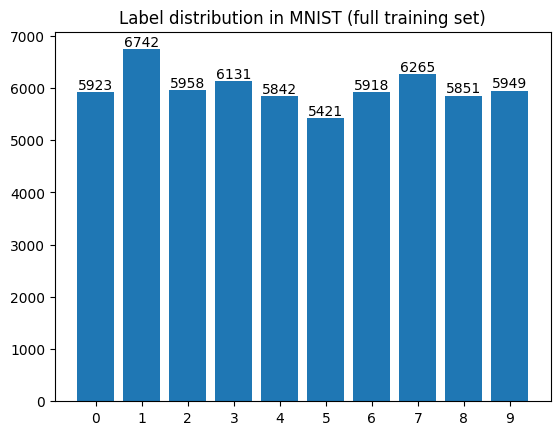

In [ ]:
all_labels = mnist["train"]["label"]
cnt = Counter(all_labels)
bar = plt.bar(cnt.keys(), cnt.values())
plt.bar_label(bar)
plt.xticks(list(cnt.keys()))
plt.title("Label distribution in MNIST (full training set)")
plt.show()

# Visualisez des exemples aléatoires

Visualisons 32 images de l'ensemble de données


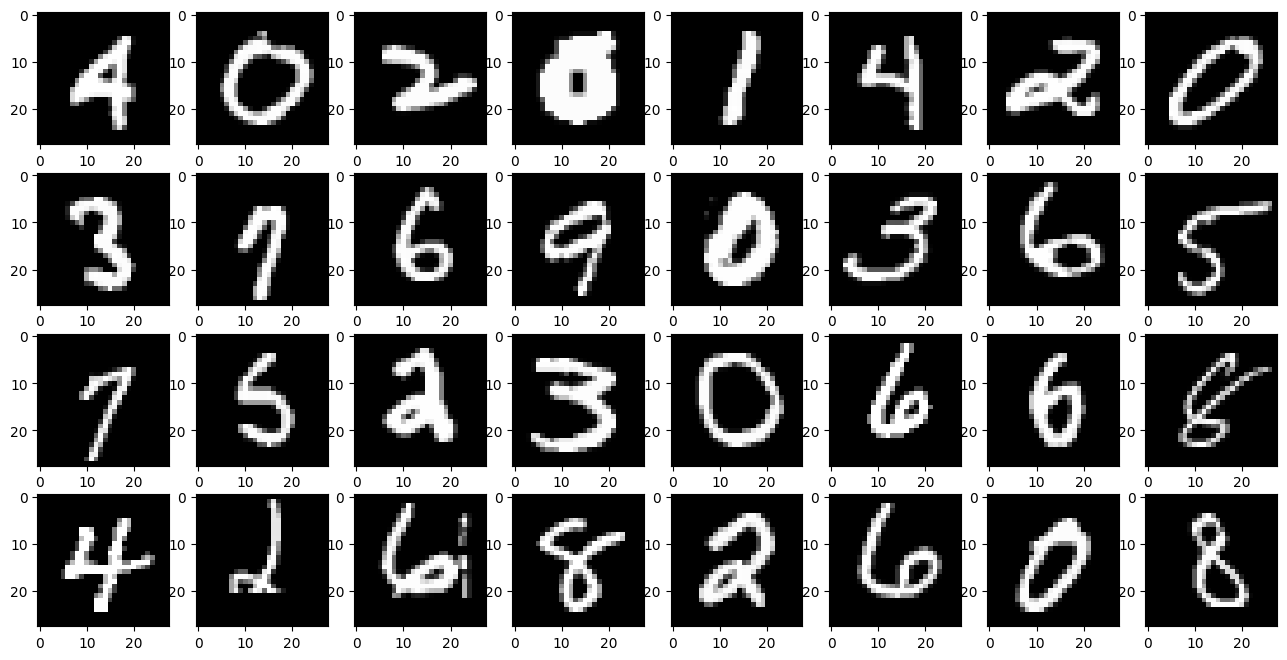

In [ ]:
def visualise_n_random_examples(trainset_, n=32):
    trainset_data = [
        Image.open(io.BytesIO(entry[0].as_py())) for entry in trainset_.data[0]
    ]
    idx = list(range(len(trainset_data)))
    random.shuffle(idx)
    idx = idx[:n]

    num_cols = 8
    num_rows = int(np.ceil(len(idx) / num_cols))
    fig, axs = plt.subplots(figsize=(16, num_rows * 2), nrows=num_rows, ncols=num_cols)
    for c_i, i in enumerate(idx):
        axs.flat[c_i].imshow(trainset_data[i], cmap="gray")

visualise_n_random_examples(mnist["train"], 32)

#2. MODÈLE CNN

Ce didacticiel ne concerne pas tant les nouvelles conceptions architecturales, nous gardons donc les choses simples et utilisons un CNN typique adapté à la tâche de classification d'images MNIST.

In [ ]:
class Net(nn.Module):
    def __init__(self, num_classes=10):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(1, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 16 * 4 * 4)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

model = Net()
sum(p.numel() for p in model.parameters())  # le nombre de paramètres du modèle.

44426

#3. FORMATION CENTRALISÉE

Une boucle de formation minimale dans PyTorch peut être construite avec trois fonctions :
* `train()` qui entraînera le modèle à l'aide d'un chargeur de données.
* `test()` qui sera utilisé pour évaluer les performances du modèle sur des données retenues, par exemple un ensemble d'entraînement.
* `run_centralised()` qui définira des éléments supplémentaires (par exemple l'optimiseur) et exécutera la boucle de formation sur N époques.

In [ ]:
def train_fn(net, trainloader, optimizer, device="cpu"):
    criterion = nn.CrossEntropyLoss()
    net.to(device)
    net.train()
    loss_accum = 0
    for batch in trainloader:
        images, labels = batch["image"].to(device), batch["label"].to(device)
        optimizer.zero_grad()
        loss = criterion(net(images), labels)
        loss.backward()
        optimizer.step()
        loss_accum += loss.item()
    return loss_accum / len(trainloader)

def test_fn(net, testloader, device="cpu"):
    criterion = nn.CrossEntropyLoss()
    net.to(device)
    net.eval()
    loss = 0
    correct = 0
    with torch.no_grad():
        for batch in testloader:
            images, labels = batch["image"].to(device), batch["label"].to(device)
            out = net(images)
            loss += criterion(out, labels).item()
            _, pred = out.max(1)
            correct += (pred == labels).sum().item()
    return loss, correct / len(testloader.dataset)

def run_centralised(trainloader, testloader, epochs=10, lr=0.01):
    model = Net()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    for e in range(epochs):
        print(f"Epoch {e+1} ....")
        train_fn(model, trainloader, opt, device)
    loss, acc = test_fn(model, testloader, device)
    print("Final:", loss, acc)

trainloader, testloader = get_mnist_dataloaders(mnist, 32)
run_centralised(trainloader, testloader, 3)

/usr/local/lib/python3.12/dist-packages/datasets/utils/_dill.py:385: DeprecationWarning: co_lnotab is deprecated, use co_lines instead.
  obj.co_lnotab,  # for < python 3.10 [not counted in args]
(raylet) [2025-12-02 20:52:51,805 E 1010 1010] (raylet) main.cc:975: Failed to establish connection to the metrics exporter agent. Metrics will not be exported. Exporter agent status: RpcError: Running out of retries to initialize the metrics agent. rpc_code: 14


Epoch 1


(pid=1058) [2025-12-02 20:53:02,282 E 1058 1138] core_worker_process.cc:825: Failed to establish connection to the metrics exporter agent. Metrics will not be exported. Exporter agent status: RpcError: Running out of retries to initialize the metrics agent. rpc_code: 14


Epoch 2
Epoch 3
Final: 11.961651236815669 0.9875


La formulation centralisée ci-dessus a très bien fonctionné pour certaines applications et pour mettre en valeur le potentiel de l’IA dans divers scénarios. Cependant, comme cela a été discuté plus tôt dans la session, la formation centralisée n'est pas adaptée à un plus grand nombre de contextes où les informations ne peuvent pas être collectées afin de créer un ensemble de données unifié (centralisé).

#4. APPRENTISSAGE FÉDÉRÉ (avec NUM_PARTITIONS Clients)

Quelles sont les principales différences entre l’apprentissage fédéré et la formation centralisée ? Si seulement vous pouviez vous choisir, vous diriez probablement :
* L'apprentissage fédéré est distribué : le modèle est formé sur l'appareil par les clients participants.
* Les données restent privées et appartiennent à un _client_ spécifique : les données ne sont jamais envoyées au serveur central.

Il existe plusieurs autres différences. Mais les deux éléments ci-dessus sont les principaux à toujours prendre en compte et qui sont communs à toutes les versions de l’apprentissage fédéré. Le reste de ce didacticiel va se concentrer sur la transformation du code que nous avons écrit jusqu'à présent pour le paramètre centralisé et sur la construction d'un pipeline d'apprentissage fédéré à l'aide de Flower et PyTorch.

Commençons !

Pour commencer à concevoir un pipeline d'apprentissage fédéré, nous devons respecter l'une des propriétés clés de FL : chaque client possède sa propre partition de données. Pour ce faire avec l'ensemble de données MNIST, nous allons générer N partitions aléatoires, où N est le nombre total de clients dans notre système FL, en utilisant [Flower Datasets](https://flower.ai/docs/datasets/). Créons 100 partitions avec [IidPartitioner](https://flower.ai/docs/datasets/ref-api/flwr_datasets.partitioner.IidPartitioner.html#flwr_datasets.partitioner.IidPartitioner) -- notez qu'il existe de nombreux autres [partitioners](https://flower.ai/docs/datasets/ref-api/flwr_datasets.partitioner.html) parmi lesquels choisir.

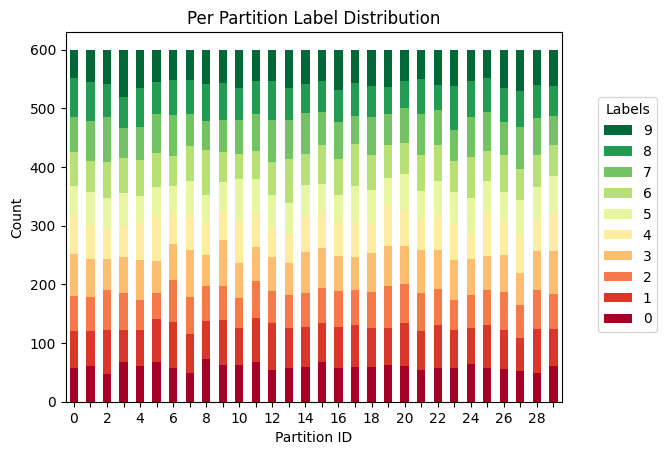

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
NUM_PARTITIONS = 100
partitioner = IidPartitioner(num_partitions=NUM_PARTITIONS)
fds = FederatedDataset(dataset="ylecun/mnist", partitioners={"train": partitioner})

# Visualisez la distribution sur les 30 premiers clients
plot_label_distributions(
    fds.partitioners["train"],
    label_name="label",
    plot_type="bar",
    size_unit="absolute",
    legend=True,
    max_num_partitions=30,
)
plt.show()

Comme vous pouvez le constater, l'histogramme de cette partition est un peu différent de celui que nous avons obtenu au début, où nous prenions en compte l'ensemble des données. Étant donné que nos partitions de données sont artificiellement construites en échantillonnant l'ensemble de données MNIST de manière IID, notre exemple d'apprentissage fédéré ne sera pas confronté à de graves problèmes d'hétérogénéité des données (ce qui est assez [active research topic](https://arxiv.org/abs/1912.04977)).

# Construire des messages

Dans Flower, le serveur et les clients communiquent en envoyant et en recevant [Message](https://flower.ai/docs/framework/ref-api/flwr.app.Message.html#flwr.app.Message)
objets. Un « Message » transporte un [RecordDict](https://flower.ai/docs/framework/ref-api/flwr.app.RecordDict.html#flwr.app.RecordDict) comme charge utile principale. Le « RecordDict »
est comme un dictionnaire Python pouvant contenir plusieurs enregistrements de types différents. Là
Il existe trois principaux types de documents :

- [ArrayRecord](https://flower.ai/docs/framework/ref-api/flwr.app.ArrayRecord.html) : contient les paramètres du modèle sous forme de dictionnaire de tableaux NumPy
- [MetricRecord](https://flower.ai/docs/framework/ref-api/flwr.app.MetricRecord.html) : contient des mesures de formation ou d'évaluation sous forme de dictionnaire de
  entiers, flottants, listes d'entiers ou listes de flottants.
- [ConfigRecord](https://flower.ai/docs/framework/ref-api/flwr.app.ConfigRecord.html#flwr.app.ConfigRecord) : Contient les paramètres de configuration sous forme de dictionnaire d'entiers,
  flottants, chaînes, booléens ou octets. Les listes de ces types sont également prises en charge.

Voyons quelques exemples de la façon de travailler avec ces types d'enregistrements et, finalement,
construire un `RecordDict` qui peut être envoyé via un `Message`.

In [ ]:
from flwr.app import ArrayRecord, MetricRecord, ConfigRecord, RecordDict

# ConfigRecord peut être utilisé pour communiquer des configurations entre ServerApp et ClientApp
# Ils peuvent contenir des scalaires, mais aussi des chaînes et des booléens
config = ConfigRecord(
    {"batch_size": 32, "use_augmentation": True, "data-path": "/my/dataset"}
)

# Les objets MetricRecord attendent des métriques basées sur scalaire (c'est-à-dire int/float/list[int]/list[float])
# En limitant les types, Flower peut agréger automatiquement les objets MetricRecord
metrics = MetricRecord({"accuracy": 0.9, "losses": [0.1, 0.001], "perplexity": 2.31})

# Les objets ArrayRecord sont conçus pour communiquer des tableaux/tenseurs/poids à partir de modèles ML
model = Net(num_classes=10)
array_record = ArrayRecord(model.state_dict())  # pour un modèle PyTorch
# Ensuite, vous pouvez reconvertir l'ArrayRecord en un state_dict PyTorch avec :
state_dict = array_record.to_torch_state_dict()

# Un RecordDict est comme un dictionnaire qui contient des enregistrements nommés.
# Il s'agit de la charge utile principale d'un message
rd = RecordDict({"my-config": config, "metrics": metrics, "my-model": array_record})

#5. APPLICATION CLIENTE

Vous pouvez considérer un client en FL comme une entité qui possède certaines données et entraîne un modèle à l'aide de ces données. La mise en garde est que le modèle est formé _de manière collaborative_ dans une fédération par plusieurs clients et, dans la plupart des cas de FL, est envoyé par un serveur central exécuté dans une « ServerApp » (nous en parlerons plus tard).

Nous pouvons définir comment la « ClientApp » effectue la formation en encapsulant une fonction avec le
Décorateur `@app.train()`. Dans ce cas, nous nommons cette fonction « train » car nous allons
utilisez-le pour entraîner le modèle sur les données locales. La fonction attend toujours deux arguments :

- A [Message](https://flower.ai/docs/framework/ref-api/flwr.app.Message.html#flwr.app.Message) : Le message reçu du serveur. Il contient le modèle
  paramètres et toute autre information de configuration envoyée par le serveur.
- A [Context](https://flower.ai/docs/framework/ref-api/flwr.app.Context.html#flwr.app.Context) : L'objet contextuel qui contient des informations sur le nœud
  l'exécution de `ClientApp` et sur l'exécution en cours.

> **Remarque** : Lors de l'exécution de Flower sur un ordinateur portable, le `run_config` dans le `Context` est toujours vide. Il est recommandé d'exécuter Flower sur le terminal via `flwr run` plutôt que dans un notebook/Colab. Consultez le [Flower Tutorial](https://flower.ai/docs/framework/tutorial-series-get-started-with-flower-pytorch.html) pour en savoir plus.


Voyons une implémentation de `ClientApp` qui utilise le PyTorch défini précédemment
Modèle CNN, applique les paramètres reçus du `ServerApp` via le message, charge
ses données locales, entraîne le modèle avec elles (en utilisant la fonction `train_fn`), et
génère une réponse `Message` contenant les paramètres du modèle mis à jour ainsi que certains
métriques intéressantes.

Dans une configuration d'apprentissage fédéré typique, la « ClientApp » implémenterait également un
Fonction `@app.evaluate()` pour évaluer le modèle reçu de `ServerApp` sur
données de validation locales. Ceci est particulièrement utile pour surveiller les performances du
modèle global sur chaque client lors de la formation. La mise en œuvre de l'évaluation
La fonction est très similaire à la fonction `train`, sauf qu'elle appelle le `test_fn`
fonction définie plus tôt dans ce tutoriel (qui implémente la boucle d'évaluation PyTorch)
et il renvoie un `Message` contenant uniquement un `MetricRecord` avec l'évaluation
métriques (pas de `ArrayRecord` car les paramètres du modèle ne sont pas mis à jour pendant
évaluation).

In [ ]:
client_app = ClientApp()

@client_app.train()
def train_client(msg: Message, context: Context):
    """Train on local client partition."""
    model = Net()
    model.load_state_dict(msg.content["arrays"].to_torch_state_dict())
    lr = msg.content["config"]["lr"]
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    partition_id = context.node_config["partition-id"]
    partition = fds.load_partition(partition_id, "train")
    train_val = partition.train_test_split(test_size=0.1, seed=42)
    trainloader, _ = get_mnist_dataloaders(train_val, 32)

    optim = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    loss = train_fn(model, trainloader, optim, device)

    return Message(
        content=RecordDict({
            "arrays": ArrayRecord(model.state_dict()),
            "metrics": MetricRecord({
                "train_loss": loss,
                "num-examples": len(trainloader.dataset),
            }),
        }),
        reply_to=msg,
    )

@client_app.evaluate()
def eval_client(msg: Message, context: Context):
    model = Net()
    model.load_state_dict(msg.content["arrays"].to_torch_state_dict())
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    partition_id = context.node_config["partition-id"]
    partition = fds.load_partition(partition_id, "train")
    train_val = partition.train_test_split(test_size=0.1, seed=42)
    _, valloader = get_mnist_dataloaders(train_val, 32)

    loss, acc = test_fn(model, valloader, device)

    return Message(
        content=RecordDict({
            "metrics": MetricRecord({
                "eval_loss": loss,
                "eval_acc": acc,
                "num-examples": len(valloader.dataset),
            })
        }),
        reply_to=msg,
    )


#6. APPLICATION SERVEUR + FedAvg

Côté serveur, nous devons configurer une stratégie qui encapsule les éléments fédérés.
approche/algorithme d'apprentissage, par exemple, *Federated Averaging* (FedAvg). La fleur a un
nombre de [built-in strategies](https://flower.ai/docs/framework/ref-api/flwr.serverapp.strategy.html#module-flwr.serverapp.strategy), mais nous pouvons également utiliser nos propres implémentations de stratégie pour
personnaliser presque tous les aspects de l’approche d’apprentissage fédéré. Pour ce tutoriel, nous
utiliser l'implémentation [FedAvg](https://flower.ai/docs/framework/ref-api/flwr.serverapp.strategy.FedAvg.html#flwr.serverapp.strategy.FedAvg) intégrée

In [ ]:
server_app = ServerApp()

@server_app.main()
def main(grid: Grid, context: Context):
    model = Net()
    arrays = ArrayRecord(model.state_dict())

    strategy = FedAvg(
        fraction_train=0.5,
        fraction_evaluate=1.0,
    )

    result = strategy.start(
        grid=grid,
        initial_arrays=arrays,
        train_config=ConfigRecord({"lr": 0.001}),
        num_rounds=5,
    )

    torch.save(result.arrays.to_torch_state_dict(), "final_model.pt")
    print("Modèle final enregistré.")

#7. EXÉCUTER UNE SIMULATION FÉDÉRÉE

Avec `ClientApp` et `ServerApp` prêts, nous pouvons lancer la simulation. Passez les deux applications à la fonction `run_simulation()` et spécifiez le nombre de `supernodes` (il s'agit d'un terme plus général utilisé dans Flower pour désigner des "nœuds" ou des "clients" individuels). Nous avons précédemment divisé l'ensemble de données en 100 partitions, une pour chaque super-nœud. Nous indiquons donc que `num_supernodes=100`.

In [ ]:
run_simulation(
    server_app=server_app,
    client_app=client_app,
    num_supernodes=NUM_PARTITIONS,
)

print("Simulation terminée !")


DEBUG:flwr:Asyncio event loop already running.
INFO :      Starting FedAvg strategy:
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      	├── Number of rounds: 5
INFO :      	├── ArrayRecord (0.17 MB)
INFO :      	├── ConfigRecord (train): {'lr': 0.001}
INFO :      	├── ConfigRecord (evaluate): (empty!)
INFO :      	├──> Sampling:
INFO :      	│	├──Fraction: train (0.50) | evaluate ( 1.00)
INFO :      	│	├──Minimum nodes: train (2) | evaluate (2)
INFO :      	│	└──Minimum available nodes: 2
INFO :      	└──> Keys in records:
INFO :      		├── Weighted by: 'num-examples'
INFO :      		├── ArrayRecord key: 'arrays'
INFO :      		└── ConfigRecord key: 'config'
INFO :      
INFO :      
INFO :      [ROUND 1/5]
INF

Saved final model.


(ClientAppActor pid=1058) WARNING :   Manually terminating ClientAppActor


Simulation complete!


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Les stratégies Flower peuvent être facilement étendues pour s'adapter à vos configurations FL ou à vos flux de travail préférés, que vous utilisiez Flower pour la recherche ou en production. Dans cette dernière section, vous apprendrez à créer une stratégie personnalisée qui se comporte comme FedAvg mais étend les fonctionnalités pour faciliter la planification LR. Ensuite, la ServerApp fera un tracé une fois l'exécution de la méthode start().

Appelons cette stratégie FedAvgCustom. Nous l'utiliserons également pour montrer comment utiliser le rappel évalue_fn, un moyen pratique d'effectuer une évaluation centralisée du modèle global après chaque tour. Notez que cette fonctionnalité est définie par l'utilisateur car elle nécessite un choix en termes de framework ML.

Le `FedAvgCustom` défini ci-dessous modifie uniquement la méthode `configure_train` de la stratégie `FedAvg`. Cette méthode est utilisée pour préparer les messages qui vont être envoyés aux `ClientApps`. Ces messages contiennent deux charges utiles principales : un « ArrayRecord » représentant le modèle à fédérer ; et un « ConfigRecord » contenant les paramètres/configurations pertinents pour les « ClientApps » participant au tour donné. Ci-dessous, nous appliquons simplement la décroissance du taux d'apprentissage tous les 5 tours en divisant par deux le LR trouvé dans l'enregistrement de configuration.

In [ ]:
from typing import Iterable
class FedAvgCustom(FedAvg):
    def configure_train(
        self, server_round: int, arrays: ArrayRecord, config: ConfigRecord, grid: Grid
    ) -> Iterable[Message]:
        """Configure the next round of federated training and maybe do LR decay."""
        # Diminuer le taux d'apprentissage d'un facteur de 0,5 tous les 5 tours
        if server_round % 5 == 0 and server_round > 0:
            config["lr"] *= 0.5
            print("LR a diminué à :", config["lr"])
        # Transmettez la configuration mise à jour et le reste des arguments à la classe parent
        return super().configure_train(server_round, arrays, config, grid)

Nous avons vu comment fonctionne l'évaluation fédérée côté client (c'est-à-dire en implémentant une fonction enveloppée avec le décorateur `@app.evaluate` dans votre `ClientApp`). Voyons maintenant comment évaluer les paramètres du modèle agrégés côté serveur.

Pour ce faire, nous devons créer une nouvelle fonction que nous pouvons nommer « central_evaluate ». Cette fonction est un rappel qui sera passé à la méthode `start` de notre stratégie. Cela signifie que la stratégie appellera cette fonction, après chaque cycle d'apprentissage fédéré, en transmettant deux arguments : le cycle actuel d'apprentissage fédéré et les paramètres du modèle agrégés.

In [ ]:
def central_evaluate(server_round: int, arrays: ArrayRecord) -> MetricRecord:
    """Evaluate model on the server side."""

    # Charger le modèle et initialiser le avec les poids reçus
    model = Net(num_classes=10)
    model.load_state_dict(arrays.to_torch_state_dict())
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    model.to(device)

    # Nous utilisons le testloader défini précédemment dans la section centralisée
    # Évaluer le modèle sur l'ensemble de test
    loss, accuracy = test_fn(model, testloader, device)

    # Renvoie les métriques d'évaluation
    return MetricRecord({"accuracy": accuracy, "loss": loss})

Avec ce qui est défini ci-dessus, il nous suffit de tout envelopper dans une `ServerApp` comme nous l'avons fait plus tôt, mais cette fois en utilisant le `FedAvgCustom` que nous venons de définir. Nous exécuterons la stratégie pendant 10 tours pour observer l'effet de la désintégration du LR.

N'oubliez pas que nous avons mentionné que ce « central_evaluate » sera appelé par la stratégie. Pour ce faire, nous devons le transmettre à la méthode « start » de la stratégie, comme indiqué ci-dessous.

In [ ]:
@server_app.main()
def main(grid: Grid, context: Context) -> None:
    """Main entry point for the ServerApp."""

    # Charger le modèle global
    global_model = Net(num_classes=10)
    arrays = ArrayRecord(global_model.state_dict())

    # Initialiser la stratégie FedAvgCustom
    strategy = FedAvgCustom(fraction_train=0.5, fraction_evaluate=1.0)

    # Stratégie de démarrage
    result = strategy.start(
        grid=grid,
        initial_arrays=arrays,
        train_config=ConfigRecord({"lr": 0.1}),
        num_rounds=10,
        evaluate_fn=central_evaluate,  # <--- ici nous passons la fonction d'évaluation
    )

    # Enregistrer le modèle final sur le disque
    print("\nEnregistrement du modèle final sur le disque...")
    state_dict = result.arrays.to_torch_state_dict()
    torch.save(state_dict, "final_model.pt")

    # faisons un tracé de la précision obtenue après chaque tour
    # Notez ici que nous utilisons les clés dans central_evaluate
    central_acc = [
        rnd["accuracy"] for rnd in result.evaluate_metrics_serverapp.values()
    ]

    plt.plot(central_acc, label="Accuracy")
    plt.xlabel("Round")
    plt.ylabel("Metric")
    plt.legend()
    plt.show()

INFO :      Starting FedAvgCustom strategy:
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      	├── Number of rounds: 10
INFO :      	├── ArrayRecord (0.17 MB)
INFO :      	├── ConfigRecord (train): {'lr': 0.1}
INFO :      	├── ConfigRecord (evaluate): (empty!)
INFO :      	├──> Sampling:
INFO :      	│	├──Fraction: train (0.50) | evaluate ( 1.00)
INFO :      	│	├──Minimum nodes: train (2) | evaluate (2)
INFO :      	│	└──Minimum available nodes: 2
INFO :      	└──> Keys in records:
INFO :      		├── Weighted by: 'num-examples'
INFO :      		├── ArrayRecord key: 'arrays'
INFO :      		└── ConfigRecord key: 'config'
INFO :      
INFO :      Initial global evaluation results: {'accuracy': 0.108, 'loss': 721.341

LR decreased to: 0.05


(ClientAppActor pid=4940) /usr/local/lib/python3.12/dist-packages/datasets/utils/_dill.py:385: DeprecationWarning: co_lnotab is deprecated, use co_lines instead.
(ClientAppActor pid=4940)   obj.co_lnotab,  # for < python 3.10 [not counted in args]
(ClientAppActor pid=4940) /usr/local/lib/python3.12/dist-packages/datasets/utils/_dill.py:385: DeprecationWarning: co_lnotab is deprecated, use co_lines instead.
(ClientAppActor pid=4940)   obj.co_lnotab,  # for < python 3.10 [not counted in args]
(ClientAppActor pid=4940) /usr/local/lib/python3.12/dist-packages/datasets/utils/_dill.py:385: DeprecationWarning: co_lnotab is deprecated, use co_lines instead.
(ClientAppActor pid=4940)   obj.co_lnotab,  # for < python 3.10 [not counted in args]
(ClientAppActor pid=4940) /usr/local/lib/python3.12/dist-packages/datasets/utils/_dill.py:385: DeprecationWarning: co_lnotab is deprecated, use co_lines instead.
(ClientAppActor pid=4940)   obj.co_lnotab,  # for < python 3.10 [not counted in args]
(ClientA

LR decreased to: 0.025


(ClientAppActor pid=4940) /usr/local/lib/python3.12/dist-packages/datasets/utils/_dill.py:385: DeprecationWarning: co_lnotab is deprecated, use co_lines instead.
(ClientAppActor pid=4940)   obj.co_lnotab,  # for < python 3.10 [not counted in args]
(ClientAppActor pid=4940) /usr/local/lib/python3.12/dist-packages/datasets/utils/_dill.py:385: DeprecationWarning: co_lnotab is deprecated, use co_lines instead.
(ClientAppActor pid=4940)   obj.co_lnotab,  # for < python 3.10 [not counted in args]
(ClientAppActor pid=4940) /usr/local/lib/python3.12/dist-packages/datasets/utils/_dill.py:385: DeprecationWarning: co_lnotab is deprecated, use co_lines instead.
(ClientAppActor pid=4940)   obj.co_lnotab,  # for < python 3.10 [not counted in args]
(ClientAppActor pid=4940) /usr/local/lib/python3.12/dist-packages/datasets/utils/_dill.py:385: DeprecationWarning: co_lnotab is deprecated, use co_lines instead.
(ClientAppActor pid=4940)   obj.co_lnotab,  # for < python 3.10 [not counted in args]
(ClientA


Saving final model to disk...


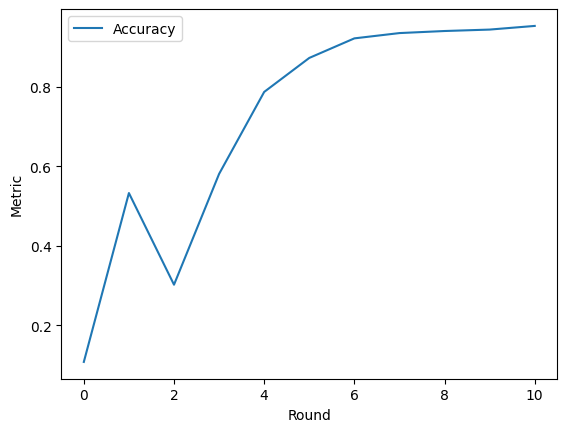

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
run_simulation(
    server_app=server_app, client_app=client_app, num_supernodes=NUM_PARTITIONS
)

**[TUTORIEL] :** Consultez le « Tutoriel sur les fleurs » pour une expérience d'apprentissage plus [step-by-step and comprehensive](https://flower.ai/docs/framework/tutorial-series-get-started-with-flower-pytorch.html). Que diriez-vous d’exécuter vos clients Flower sur le GPU ? Découvrez comment procéder dans le [Flower Simulation Documentation](https://flower.ai/docs/framework/how-to-run-simulations.html)